In [ ]:
# Реализовать преобразование Хаара (3 ступени сжатия)
# Исходное изображение 512x512

In [3]:
import numpy as np
import cv2
from matplotlib import pyplot as plt
import copy

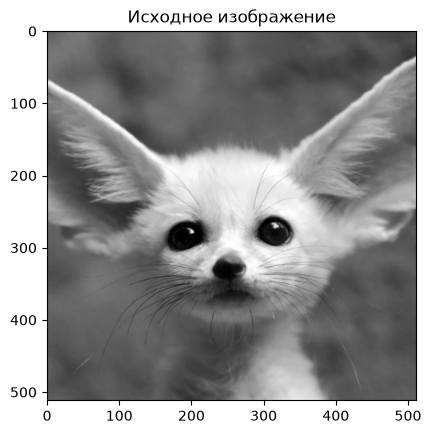

In [4]:
image = cv2.imread('pen.png')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

height, width = image_gray.shape

plt.title('Исходное изображение')
plt.imshow(image_gray, cmap='gray')
plt.show()

In [5]:
# Реализовать преобразование Хаара
def haar2d(img):

    row_low = (img[:, 0::2] + img[:, 1::2]) / 2.0
    row_high = (img[:, 0::2] - img[:, 1::2]) / 2.0

    LL = (row_low[0::2, :] + row_low[1::2, :]) / 2.0
    LH = (row_low[0::2, :] - row_low[1::2, :]) / 2.0

    HL = (row_high[0::2, :] + row_high[1::2, :]) / 2.0
    HH = (row_high[0::2, :] - row_high[1::2, :]) / 2.0

    top = np.hstack((LL, HL))
    bottom = np.hstack((LH, HH))

    return np.vstack((top, bottom))


image_float = np.float32(image_gray)

haar_1 = haar2d(image_float)

haar_2 = haar_1.copy()
h, w = haar_1.shape
haar_2[:h//2, :w//2] = haar2d(haar_1[:h//2, :w//2])

haar_3 = haar_2.copy()
haar_3[:h//4, :w//4] = haar2d(haar_2[:h//4, :w//4])




(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

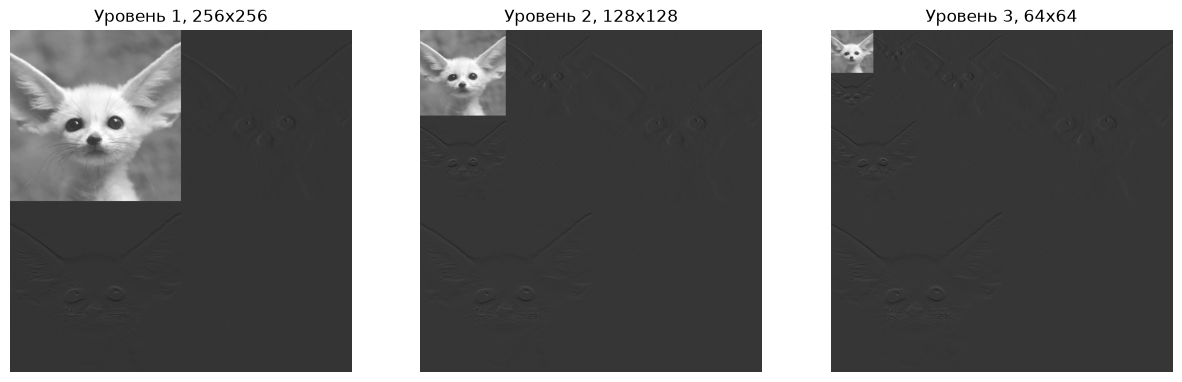

In [6]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(haar_1, cmap='gray')
plt.title(f'Уровень 1, {width//2}x{height//2}')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(haar_2, cmap='gray')
plt.title(f'Уровень 2, {width//4}x{height//4}')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(haar_3, cmap='gray')
plt.title(f'Уровень 3, {width//8}x{height//8}')
plt.axis('off')